# Data Cleaning
In this file, we're gonna focus on the cleaning of our dataset, by:
- Handling of missing values (NaN) and incorrect values
- Train/Test Split
- Removal of Identifiers (IDs and Dates)
- Correlation Analysis (Redundancy and Features Selection)
- Normalization (Min-Max Scaling)
- Export new datasets
- Summary

### 1. Dataset

In [110]:
DATA_PATH = "../data/daily_injury_data.csv"

### 2. Imports

In [111]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from IPython.display import display

### 3. Handling of missing values (NaN) and incorrect values

In this step, we performed an analysis of missing values to ensure the integrity of our data before modeling.

#### 3.1. Identification of Missing Values

We first verified that were no standard `NaN`values in the dataset. However, we identified that a negative value (-0.01) indicated a lack of data, similar to `NaN`in other datasets.

In [112]:
df = pd.read_csv(DATA_PATH)

# check NaNs 
total_nans = df.isna().sum().sum()
print(f"Total NaN values in the dataset: {total_nans}\n")

Total NaN values in the dataset: 0



#### 3.2. Percentage Analysis 

We found that the `-0.01` values appear in the subjective columns, such as *perceived exertion, perceived.trainingSuccess and perceived.recovery*.
Due to the low percentage (27%) of missing data in the column, we decided to not drop them.

In [113]:
# check for negative values
total_rows = len(df)
negative_counts = (df < 0).sum()
cols_with_negatives = negative_counts[negative_counts > 0]

# calculate the percentage of negative values per column
percent_negatives = (cols_with_negatives / total_rows) * 100

negative_analysis = pd.DataFrame({
    'Percentage (%)': percent_negatives.round(2)
})
display(negative_analysis)
print("Table 1: Percentage of Missing Values in Columns\n")

,Percentage (%)
perceived exertion,26.83
perceived trainingSuccess,26.83
perceived recovery,26.83
perceived exertion.1,26.90
perceived trainingSuccess.1,26.90
perceived recovery.1,26.90
perceived exertion.2,26.84
perceived trainingSuccess.2,26.84
perceived recovery.2,26.84
perceived exertion.3,26.84


Table 1: Percentage of Missing Values in Columns



#### 3.3. Finding when Negative Values Appear

After analysing, we thought that that athletes didn't fill the subjective questionnaire on the days they did not train.
To confirm this, we cross-referenced the `-0.01` entries with the physical training columns, like *total km*.
This process confirmed that on 100% of the days without a questionnaire, the maximum physical load were exactly `0.0`.

In [114]:
days_without_quest = df[df['perceived exertion'] == -0.01]
days_with_quest = df[df['perceived exertion'] != -0.01]
physical_cols = ['total km', 'km Z3-4', 'km sprinting', 'hours alternative']

# create a comparative dataframe
comparison_df = pd.DataFrame({
    'No Questionnaire (-0.01)': days_without_quest[physical_cols].sum(),
    'With Questionnaire (Valid)': days_with_quest[physical_cols].sum()
})

styled_comparison = comparison_df.style.set_properties(**{'text-align': 'center'}).format("{:.1f}")

display(styled_comparison)
print("Table 2: Total Accumulated Physical Load Comparison\n")

,No Questionnaire (-0.01),With Questionnaire (Valid)
total km,0.0,300995.1
km Z3-4,0.0,29567.6
km sprinting,0.0,3122.6
hours alternative,0.0,6991.9


Table 2: Total Accumulated Physical Load Comparison



#### 3.4. Interpretation of Zero Values

Columns like `total km` and `nr. sessions` have a lot of zeros. It’s important to clarify that these aren't errors or missing information, they are **Rest Days**. 

These days account for about 27% of our dataset. From a sports science perspective, we can't just treat them as "empty" data. If we removed these zeros, the model would only see training load and would never learn to recognize the difference between a healthy training-rest cycle and dangerous overtraining.

### 4. Train/Test Split

After handling missing and incorrect values in the dataset, the next step is to split the data into Training and Testing sets.
In this dataset, we decided not to use a standard random split because it would cause two critical failures:
- **Data Leakage:** Due to the 7-day sliding window technique, consecutive rows share 6 days of data.
A random split would place overlapping windows in both sets, allowing the model to "cheat" by seeing testing data during training.
- **Class Imbalance:** Injury events are very rare in this dataset. A random split could result in a testing set with zero injury cases, which would make the model evaluation impossible

To solve this, we implemented a **Stratified Group Split**. We first grouped the data by `Athlete ID` to ensure temporal and athlete isolation. 
While it might seem logical to address the Class Imbalance by randomly splitting individual days (rows) to guarantee a proportional number of injuries in both sets, doing so would destroy the athlete's isolation and trigger the Data Leakage problem mentioned above.

Therefore, we prioritized temporal integrity and created two different groups based on their injury history and sampled 80% of each group for the Training set and 20% for the Testing set.

In [115]:
# identify which athletes had an injury
athlete_injury_history = df.groupby('Athlete ID')['injury'].sum() > 0

injured_athletes = athlete_injury_history[athlete_injury_history == True].index.to_numpy()
healthy_athletes = athlete_injury_history[athlete_injury_history == False].index.to_numpy()
print(f"Number of athletes that had an injury: {len(injured_athletes)}")
print(f"Number of athletes that didn't have an injury: {len(healthy_athletes)}")

# training and testing split
np.random.seed(42)

train_injured = np.random.choice(injured_athletes, size=int(0.8 * len(injured_athletes)), replace=False)
train_healthy = np.random.choice(healthy_athletes, size=int(0.8 * len(healthy_athletes)), replace=False)

# combine IDs for the Training set
train_ids = np.concatenate([train_injured, train_healthy])

# split the DataFrame based on training IDs
train_df = df[df['Athlete ID'].isin(train_ids)].copy()
test_df = df[~df['Athlete ID'].isin(train_ids)].copy()

total_rows = len(df)
total_injuries = df['injury'].sum()

# percentages calculation
train_rows_pct = (len(train_df) / total_rows) * 100
test_rows_pct = (len(test_df) / total_rows) * 100
train_inj_pct = (train_df['injury'].sum() / total_injuries) * 100
test_inj_pct = (test_df['injury'].sum() / total_injuries) * 100

print("--- Training and Testing Split ---")
print(f"Training Set: {len(train_df)} rows ({train_rows_pct:.1f}% of total data) | Injury Events: {train_df['injury'].sum():.0f} ({train_inj_pct:.1f}% of all known injuries)")
print(f"Testing Set:  {len(test_df)} rows ({test_rows_pct:.1f}% of total data)  | Injury Events: {test_df['injury'].sum():.0f} ({test_inj_pct:.1f}% of all known injuries)\n")

Number of athletes that had an injury: 63
Number of athletes that didn't have an injury: 11
--- Training and Testing Split ---
Training Set: 33434 rows (78.2% of total data) | Injury Events: 435 (74.6% of all known injuries)
Testing Set:  9332 rows (21.8% of total data)  | Injury Events: 148 (25.4% of all known injuries)



### 5. Removal of Identifiers (IDs and Dates)

After the split, we must remove the identifying columns (`Athlete ID` and `Date`) so the model can learn to recognize patterns that lead to an injury rather than memorizing specific athletes.

- **Athlete ID:** This column should be removed to prevent the model of learning that a specific athlete gets frequently injured.
- **Date:** This column should also be removed to avoid the model to find temporal correlations that won't exist in the future.

This removal will have in mind the previously separated `train_df` and `test_df` to ensure that our Training and Testing sets remain isolated.

In [116]:
# saves IDs and Dates to compare it in the future
test_identifiers = test_df[['Athlete ID', 'Date']].copy()

cols_to_drop = ['Athlete ID', 'Date']

X_train = train_df.drop(columns=cols_to_drop + ['injury'])
y_train = train_df['injury']

X_test = test_df.drop(columns=cols_to_drop + ['injury'])
y_test = test_df['injury']

print(f"Number of features in the original dataset: {df.shape[1]}")
print("---Identifiers and Target removed from X matrices ---")
print(f"Training set: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Testing set:  {X_test.shape[0]} rows, {X_test.shape[1]} features")

Number of features in the original dataset: 73
---Identifiers and Target removed from X matrices ---
Training set: 33434 rows, 70 features
Testing set:  9332 rows, 70 features


**Note:** We have stored the IDs and Dates of the test set in `test_identifiers`. This ensures that the model remains completely unaware of these identifiers during evaluation to prevent bias.
However, we can later map the model's predictions back to real athletes and dates from prehensive error analysis and results interpretation.

### 6. Correlation Analysis (Redundancy and Features Selection)

In this step, we analyze the relationships between training variables to identify potential redundacies when the correlation value is higher than 0.85.

To maintain a clear analysis, we focused on the current day's metrics, because since our dataset uses a 7-day sliding window, the majority of the columns are time-shifted versions of these variables. Therefore, any redundancy found in today's data will exist across all days in the window.

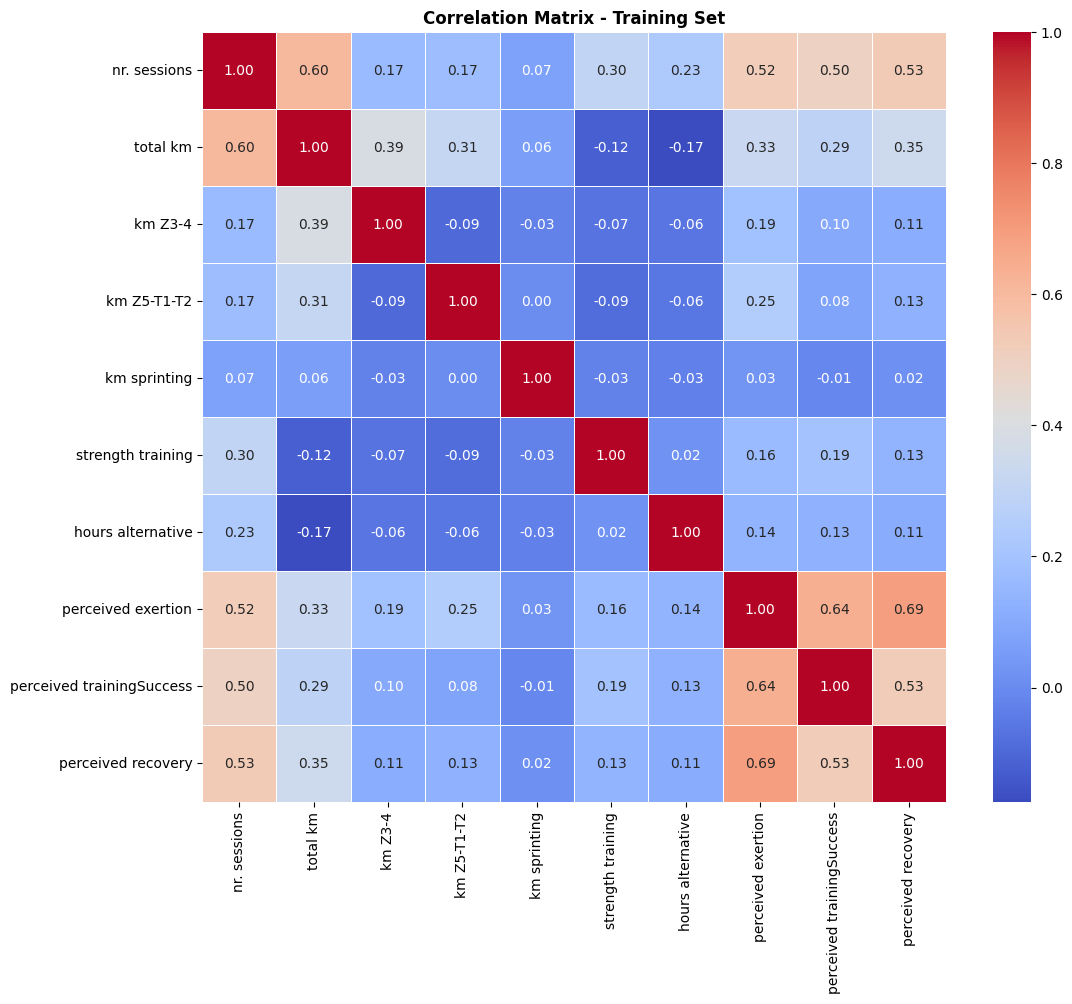

In [117]:
# to identify repetitive columns
lag_suffixes = ('.1', '.2', '.3', '.4', '.5', '.6')

base_cols = [col for col in X_train.columns if not col.endswith(lag_suffixes)]
corr_matrix = X_train[base_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix - Training Set", fontweight='bold')
plt.show()

#### 6.1. Matrix Analysis
The correlation matrix revealed that no variables exceeded the 0.85 threshold, so no features were removed.
We observed a small high correlation between `nr_sessions` and `total_kms`, but the highest correlation found was 0.69 betweem `perceived exertion` and `perceived recovery`.

#### 6.2. Modeling Strategy
Given that subjective features are the ones with higher correlation values, we have decided to implement two different strategies for the model in the next phase:
- **Full Model:** Using all 70 features (objectives and subjectives).
- **Objectives-Only Model:** Excluding the subjective data given by the athletes.

In [118]:
# Features for the Objectives-Only Model
X_train_objective = X_train.loc[:, ~X_train.columns.str.contains('perceived')]
X_test_objective = X_test.loc[:, ~X_test.columns.str.contains('perceived')]

### 7. Normalization (Min-Max Scaling)

In this final step, we transform all features to a common scale between 0 and 1, because due to the different ranges between columns, the model might worngly assume that larger numbers are important.

We chose **Min-Max Normalization** over Standardization because it preserves the relationship between training and rest days.
In our dataset, a value of 0 represents a rest day and if we chose Standardization, it would be transformed into a negative value, which would make it harder for the model to distinguish betweem low-effort days and actual recovery days.

In [122]:
scaler = MinMaxScaler()

# full model features normalization
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

display(X_train.head())
print("Table 3: Normalization Full Model\n")

,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,...,nr. sessions.6,total km.6,km Z3-4.6,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6
0,0.5,0.105455,0.0,0.0125,0.03,0.0,0.000000,0.118812,0.009901,0.188119,...,0.5,0.000000,0.000000,0.000000,0.00,0.0,0.05,0.108911,0.009901,0.158416
1,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.000000,0.000000,0.000000,...,0.5,0.094545,0.000000,0.010417,0.03,0.0,0.00,0.108911,0.009901,0.178218
2,0.5,0.000000,0.0,0.0000,0.00,0.5,0.000000,0.108911,0.009901,0.178218,...,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.00,0.000000,0.000000,0.000000
3,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.000000,0.000000,0.000000,...,0.5,0.000000,0.000000,0.000000,0.00,0.5,0.00,0.108911,0.009901,0.178218
4,0.5,0.000000,0.0,0.0000,0.00,0.0,0.105675,0.089109,0.009901,0.188119,...,0.5,0.320000,0.170616,0.000000,0.00,0.0,0.00,0.118812,0.009901,0.178218


Table 3: Normalization Full Model



In [123]:
# objectives-only model features normalization
scaler_obj = MinMaxScaler()
X_train_obj_scaled = scaler_obj.fit_transform(X_train_objective)
X_test_obj_scaled = scaler_obj.transform(X_test_objective)

X_train_objective = pd.DataFrame(X_train_obj_scaled, columns=X_train_objective.columns, index=X_train_objective.index)
X_test_objective = pd.DataFrame(X_test_obj_scaled, columns=X_test_objective.columns, index=X_test_objective.index)

display(X_train_objective.head())
print("Table 4: Normalization Objectives-Only Model\n")

,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,nr. sessions.1,total km.1,km Z3-4.1,...,km sprinting.5,strength training.5,hours alternative.5,nr. sessions.6,total km.6,km Z3-4.6,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6
0,0.5,0.105455,0.0,0.0125,0.03,0.0,0.000000,0.0,0.000000,0.000000,...,0.00,0.5,0.000000,0.5,0.000000,0.000000,0.000000,0.00,0.0,0.05
1,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.5,0.000000,0.000000,...,0.00,0.0,0.103413,0.5,0.094545,0.000000,0.010417,0.03,0.0,0.00
2,0.5,0.000000,0.0,0.0000,0.00,0.5,0.000000,0.0,0.000000,0.000000,...,0.03,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.0,0.00
3,0.0,0.000000,0.0,0.0000,0.00,0.0,0.000000,0.5,0.000000,0.000000,...,0.00,0.0,0.000000,0.5,0.000000,0.000000,0.000000,0.00,0.5,0.00
4,0.5,0.000000,0.0,0.0000,0.00,0.0,0.105675,0.5,0.298182,0.236967,...,0.00,0.5,0.000000,0.5,0.320000,0.170616,0.000000,0.00,0.0,0.00


Table 4: Normalization Objectives-Only Model



### 8. Export new datasets

In [125]:
X_train.to_csv("../data/X_train_final.csv", index=True)
X_test.to_csv("../data/X_test_final.csv", index=True)
y_train.to_csv("../data/y_train_final.csv", index=True)
y_test.to_csv("../data/y_test_final.csv", index=True)

X_train_objective.to_csv("../data/X_train_obj_final.csv", index=True)
X_test_objective.to_csv("../data/X_test_obj_final.csv", index=True)

print("✓ All 6 datasets (Full and Objective versions) exported to ../data/")
print("Cleaning and Preprocessing phase successfully completed!")

✓ All 6 datasets (Full and Objective versions) exported to ../data/
Cleaning and Preprocessing phase successfully completed!


### 9. Summary

1.  **Full Dataset:** 70 features (including 21 subjective metrics).
2.  **Objective Dataset:** 49 features (strictly physical load metrics).

**Final Dataset Integrity:**
- **Zero Values:** Maintained as 0.0 to represent recovery/rest periods.
- **Scaling:** All features are now normalized within the [0, 1] range.
- **Leakage Prevention:** Training and testing sets remain completely isolated by athlete and scale distribution.
- **Target:** The `injury` column is isolated in `y_train` and `y_test`, ready for supervised learning.